# Flash-Decoding from scratch: splitting the KV cache

*Notebook 4 of 6. Prerequisite: the $(m,\ell)$ merge from notebook 1. Everything is re-defined here.*

**TL;DR.** During autoregressive decoding the query has length 1 and the KV cache can be tens of thousands of tokens long. FlashAttention-2 parallelises over batch, heads and *query blocks*, so with a single query token it exposes only `batch x heads` independent work items, which can be far fewer than the 108 SMs of an A100. Flash-Decoding (Dao, Haziza, Massa and Sizov, 2023, [blog post](https://crfm.stanford.edu/2023/10/12/flashdecoding.html)) adds one more parallel dimension by **splitting the keys and values into chunks**, computing a partial attention result per chunk on a different SM, and merging the partial results with the log-sum-exp rule. The blog *reports* up to 8x faster generation for very long sequences (reported, not measured here). In this notebook we build the split-and-merge algorithm, prove it exact for any split count and any merge order, count the extra traffic it costs (under 1% in our setting), and show where it fails if empty chunks are not handled.

**Scope.** Runs on CUDA or CPU (`FA_DEVICE` overrides). We measure exactness and memory-traffic counts directly. SM occupancy is a model with stated assumptions, and we do not turn it into a speedup number.

**Contents**
1. The decoding problem
2. Merging partial attention results
3. Split-KV decoding
4. Choosing the number of splits
5. Ragged batches and the empty-chunk bug
6. Merge order does not matter
7. Cost
8. Closing thoughts

In [1]:
import math, numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from fa_kit import *
torch.manual_seed(0); HEAD = {}; print('device:', DEVICE)

device: cpu


## 1. The decoding problem

**A tiny example.** A model is generating token 4097 of a sequence. The new token's query $q\in\mathbb R^{d}$ attends to all 4096 cached keys. The attention matrix is $1\times4096$, there is no $N\times N$ matrix to avoid, and the work is a single pass over $K$ and $V$: about $2Nd$ elements read for $4Nd$ FLOPs, i.e. 2 FLOP per element, far below the A100 ridge point of roughly 200 FLOP/byte (derived in notebook 1 from reported specs). Decoding attention is purely **memory-bandwidth bound**, so what matters is keeping enough SMs pulling data from HBM at once.

**General definition.** For batch $B$, heads $H$, cache length $N$, FA-2 launches $B\cdot H\cdot\lceil N_q/B_r\rceil$ thread blocks. With $N_q=1$ that is $B\cdot H$.

  B   H | FA-2 thread blocks | SMs idle (of 108)
  1  32 |                 32 |    76  (70%)
  1   8 |                  8 |   100  (93%)
  4  32 |                128 |     0  (0%)
  8  32 |                256 |     0  (0%)
  1   1 |                  1 |   107  (99%)

per head, N=4096, d=64: 524k elements read, 1.05 MFLOP -> 1.0 FLOP/byte (fp16)


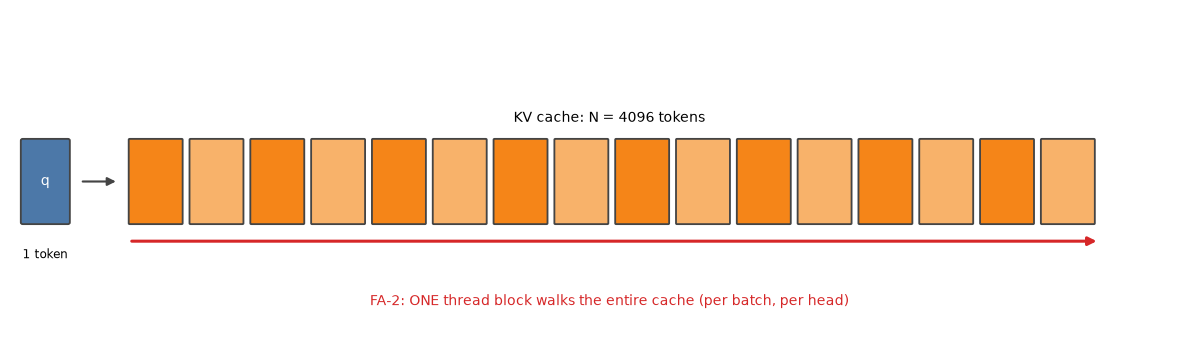

<sub>**Figure.** With one query token there is nothing to split along the query axis, so a single thread block reads the whole cache for each head. Notice that the amount of data (the orange strip) is large while the parallelism is tiny: that mismatch is the whole problem.</sub>

In [2]:
SM = 108
print(f"{'B':>3} {'H':>3} | FA-2 thread blocks | SMs idle (of {SM})")
for B_, H_ in [(1, 32), (1, 8), (4, 32), (8, 32), (1, 1)]:
    w = B_ * H_; print(f"{B_:>3} {H_:>3} | {w:>18} | {max(SM - w, 0):>5}  ({max(SM - w, 0)/SM*100:.0f}%)")
N, d = 4096, 64; elems = 2 * N * d; flops = 4 * N * d
print(f"\nper head, N={N}, d={d}: {elems/1e3:.0f}k elements read, {flops/1e6:.2f} MFLOP -> {flops/(elems*2):.1f} FLOP/byte (fp16)")
check("decoding attention is far below the ~200 FLOP/byte ridge point", flops / (elems * 2) < 10)
fig, ax = plt.subplots(figsize=(11, 3.4)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 4)
box(ax, .1, 1.5, .5, 1.0, "q", COL["q"], tc="w"); ax.text(.35, 1.1, "1 token", ha="center", fontsize=8)
for i in range(16): box(ax, 1.2 + i * .62, 1.5, .55, 1.0, "", COL["k"] if i % 2 == 0 else "#F8B26A", round_=.01)
ax.text(6.1, 2.7, "KV cache: N = 4096 tokens", ha="center", fontsize=9)
ax.text(6.1, .55, "FA-2: ONE thread block walks the entire cache (per batch, per head)", ha="center", fontsize=9, color=COL["bad"])
arrow(ax, (.7, 2.0), (1.1, 2.0)); arrow(ax, (1.2, 1.3), (11.1, 1.3), color=COL["bad"], lw=2)
plt.tight_layout(); plt.show()
caption("With one query token there is nothing to split along the query axis, so a single thread block reads the whole cache for each head. Notice that the amount of data (the orange strip) is large while the parallelism is tiny: that mismatch is the whole problem.")

The fix needs a way to let *different* SMs each read a different part of the cache and then combine what they found. That requires only the merge rule from online softmax, applied to finished partial results rather than to a running state.

## 2. Merging partial attention results

**A tiny example.** Reuse the row from notebook 1: scores $[1,2,3,4]$, values $[10,20,30,40]$, split into chunk A (first two) and chunk B (last two). Each chunk is processed independently and returns a *normalised* local output $o_s$ and its log-sum-exp $L_s=\log\sum_j e^{x_j}$. The merged output is a weighted average of the $o_s$ with weights $\mathrm{softmax}(L_1,\dots,L_S)$.

In [3]:
x = torch.tensor([1., 2., 3., 4.]); vv = torch.tensor([10., 20., 30., 40.])
chunks = [(x[:2], vv[:2]), (x[2:], vv[2:])]
o_s = torch.stack([torch.softmax(a, 0) @ b for a, b in chunks]); L_s = torch.stack([torch.logsumexp(a, 0) for a, _ in chunks])
w = torch.softmax(L_s, 0)
print("local outputs o_s :", o_s.tolist()); print("local L_s         :", L_s.tolist()); print("weights softmax(L):", w.tolist())
print("merged            :", (w @ o_s).item(), "  direct:", (torch.softmax(x, 0) @ vv).item())
check("tiny merge equals direct attention", abs((w @ o_s) - torch.softmax(x, 0) @ vv) < 1e-5)

local outputs o_s : [17.31058692932129, 37.310585021972656]
local L_s         : [2.3132617473602295, 4.31326150894165]
weights softmax(L): [0.11920294165611267, 0.8807970285415649]
merged            : 34.9265251159668   direct: 34.9265251159668


tensor(True)

**General definition.** Let chunk $s$ hold keys $\mathcal J_s$ and return $o_s=\sum_{j\in\mathcal J_s}\mathrm{softmax}_{\mathcal J_s}(x)_jv_j$ and $L_s=\log\sum_{j\in\mathcal J_s}e^{x_j}$. Then

$$L=\log\sum_s e^{L_s},\qquad o=\sum_s e^{L_s-L}\,o_s .$$

*Why it holds:* $e^{L_s}$ is the total (unnormalised) softmax weight of chunk $s$, so $e^{L_s-L}$ is the fraction of the full softmax mass it carries; scaling each local average by that fraction recovers the global one.

**How it is implemented.** The kernel returns $(\tilde o_s,m_s,\ell_s)$ per chunk, the unnormalised sum with its running max and sum, which is what FA-2's inner loop already holds. The merge uses $m=\max_sm_s$ for numerical safety. We define both functions below, including the guard for an all-masked chunk ($m_s=-\infty$) that section 5 shows is necessary.

In [4]:
def partial_attention(q, Kc, Vc, valid=None):
    """One chunk. q:(Nq,d), Kc,Vc:(n,d). Returns unnormalised O~ (Nq,d), max m (Nq,), sum l (Nq,). All-masked rows return (0,-inf,0)."""
    S = (q @ Kc.T) / math.sqrt(q.shape[-1])
    if valid is not None: S = S.masked_fill(~valid[None, :], float("-inf"))
    m = S.max(1).values; ms = torch.where(torch.isinf(m), torch.zeros_like(m), m)      # guard: -inf - (-inf) would be nan
    P = torch.exp(S - ms[:, None]); return P @ Vc, m, P.sum(1)

def merge_partials(parts):
    """Combine [(O~,m,l), ...] -> (O, L). Associative; any grouping gives the same result."""
    m = torch.stack([p[1] for p in parts]).max(0).values; msafe = torch.where(torch.isinf(m), torch.zeros_like(m), m)
    scale = [torch.exp(p[1] - msafe) for p in parts]                                   # exp(-inf)=0 drops empty chunks
    l = sum(s * p[2] for s, p in zip(scale, parts)); Ot = sum(s[:, None] * p[0] for s, p in zip(scale, parts))
    return Ot / l[:, None], msafe + torch.log(l)

a, b, c = (torch.randn(5, 8, dtype=torch.float64) for _ in range(3)); k_, v_ = torch.randn(40, 8, dtype=torch.float64), torch.randn(40, 8, dtype=torch.float64)
O1, L1 = merge_partials([partial_attention(a, k_[:17], v_[:17]), partial_attention(a, k_[17:], v_[17:])]); Or, Lr = ref_attention(a, k_, v_)
print("2-way merge: max|O-ref| =", max_err(O1, Or), " max|L-ref| =", max_err(L1, Lr))
check("merge_partials reproduces full attention (2 uneven chunks)", max_err(O1, Or) < 1e-12 and max_err(L1, Lr) < 1e-12)

2-way merge: max|O-ref| = 2.220446049250313e-16  max|L-ref| = 0.0


True

With the merge in place, the algorithm is two stages.

## 3. Split-KV decoding

**A tiny example.** Cache of 16 tokens, 4 splits of 4 keys each. Stage 1 runs four independent partial attentions (one per SM); stage 2 merges four tuples.

**How it is implemented.** Stage 1 is a kernel with grid $(B\cdot H, S)$; each block reads its chunk of $K,V$ once and writes $(\tilde o_s,m_s,\ell_s)$, which is $d+2$ numbers per chunk, to HBM. Stage 2 is a small reduction kernel. We count the HBM traffic of both stages.

In [5]:
def flash_decode(q, K, V, n_splits, valid=None, io=None):
    """q:(Nq,d); K,V:(N,d). Stage 1: independent chunks (parallel on a GPU). Stage 2: merge."""
    N, d = K.shape; io = io if io is not None else IOCounter(); Nq = q.shape[0]
    bounds = np.linspace(0, N, n_splits + 1).round().astype(int); parts = []
    for s in range(n_splits):
        lo, hi = bounds[s], bounds[s + 1]
        if hi == lo: continue
        io.read("K", (hi - lo) * d); io.read("V", (hi - lo) * d); io.read("q", Nq * d)                  # each SM reads its own chunk once
        parts.append(partial_attention(q, K[lo:hi], V[lo:hi], None if valid is None else valid[lo:hi]))
        io.write("partial", Nq * (d + 2))                                                                  # O~, m, l written to HBM
    io.read("partial", Nq * (d + 2) * len(parts)); O, L = merge_partials(parts); io.write("O", O)       # stage 2
    return O, L

qd = torch.randn(1, 64, dtype=torch.float64); Kd, Vd = torch.randn(4096, 64, dtype=torch.float64), torch.randn(4096, 64, dtype=torch.float64)
Or, Lr = ref_attention(qd, Kd, Vd)
split_errs = {}
for S_ in (1, 2, 3, 7, 16, 33, 128):
    O_, L_ = flash_decode(qd, Kd, Vd, S_); split_errs[S_] = max(max_err(O_, Or), max_err(L_, Lr))
    check(f"split-KV exact with {S_} splits (incl. uneven)", split_errs[S_] < 1e-12, f"err={split_errs[S_]:.1e}")
print("max error over split counts:", max(split_errs.values()))
q4 = torch.randn(4, 64, dtype=torch.float64); O4, _ = flash_decode(q4, Kd, Vd, 8); check("works for Nq>1 (e.g. speculative decoding, Nq=4)", max_err(O4, ref_attention(q4, Kd, Vd)[0]) < 1e-12)

max error over split counts: 1.5959455978986625e-16


True

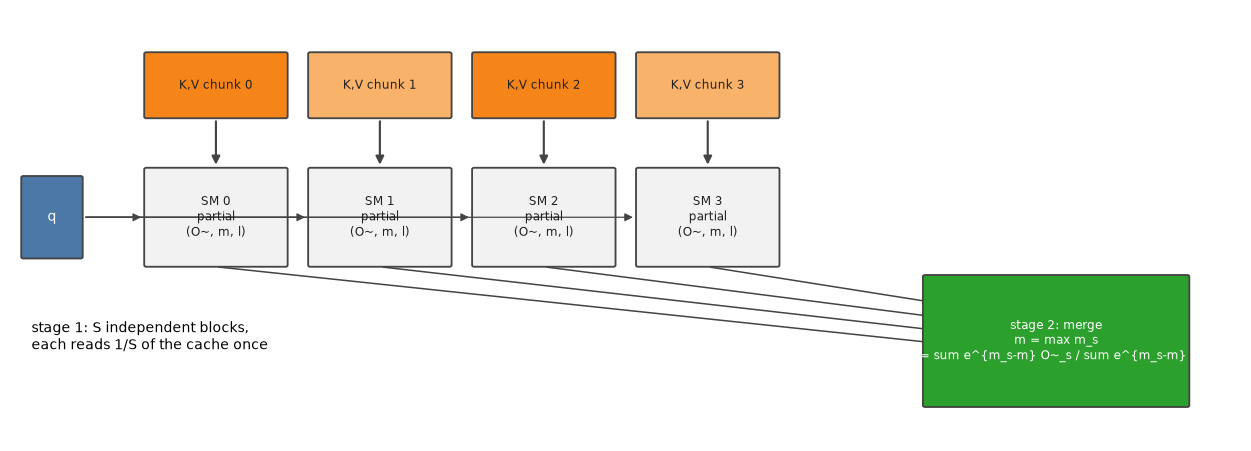

<sub>**Figure.** Stage 1 reads each K/V element exactly once, same as unsplit attention; the only new traffic is the small (d+2)-number partial each SM writes, and the reduction in stage 2 reads them back. Notice that the four SMs run concurrently, so the time to stream the cache is divided by about S as long as HBM is not yet saturated.</sub>

In [6]:
# Figure: the two-stage dataflow
fig, ax = plt.subplots(figsize=(11.5, 4.2)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 5.2)
box(ax, .1, 2.2, .6, 1.0, "q", COL["q"], tc="w")
cols = ["#F58518", "#F8B26A"]
for s in range(4):
    x0 = 1.3 + s * 1.6; box(ax, x0, 3.9, 1.4, .8, f"K,V chunk {s}", cols[s % 2], fs=8); box(ax, x0, 2.1, 1.4, 1.2, f"SM {s}\npartial\n(O~, m, l)", COL["soft"], fs=8); arrow(ax, (x0 + .7, 3.9), (x0 + .7, 3.3)); arrow(ax, (.7, 2.7), (x0, 2.7), lw=.8)
    arrow(ax, (x0 + .7, 2.1), (9.6, 1.1 + .15 * s), lw=1.0)
box(ax, 8.9, .4, 2.6, 1.6, "stage 2: merge\nm = max m_s\nO = sum e^{m_s-m} O~_s / sum e^{m_s-m} l_s", COL["good"], tc="w", fs=8)
ax.text(.2, 1.1, "stage 1: S independent blocks,\neach reads 1/S of the cache once", fontsize=9)
plt.tight_layout(); plt.show()
caption("Stage 1 reads each K/V element exactly once, same as unsplit attention; the only new traffic is the small (d+2)-number partial each SM writes, and the reduction in stage 2 reads them back. Notice that the four SMs run concurrently, so the time to stream the cache is divided by about S as long as HBM is not yet saturated.")

The split is exact for every count we tried, including counts that do not divide $N$. The remaining question is how many splits to use.

## 4. Choosing the number of splits

**A tiny example.** One sequence, 8 heads, 108 SMs: $8$ blocks leave 100 SMs idle. With $S=16$ splits there are $128$ blocks, which fill the GPU in 2 waves (the second wave is 20/108 full). A rule of thumb is to choose $S$ so that $B\cdot H\cdot S$ reaches at least the SM count, but no more than $N/\text{min\_chunk}$ so each chunk still amortises its launch and its partial write.

**General definition (our heuristic, not taken from any library).** $S=\min\big(\lceil\text{SM}/(BH)\rceil,\ \lfloor N/c_{\min}\rfloor\big)$ with $c_{\min}=128$ keys, at least 1. We measure two things: the fraction of SMs with work, and the extra HBM traffic. We do **not** turn occupancy into a speed claim, since an SM can pull more than its fair share of bandwidth and the real gain depends on that.

  BH       N | S  | blocks | SMs busy before -> after | extra traffic
   1    2048 | 16 |     16 |      1% ->   15%        | 0.81%
   1   16384 | 108 |    108 |      1% ->  100%        | 0.68%
   1  131072 | 108 |    108 |      1% ->  100%        | 0.08%
   8    2048 | 14 |    112 |      7% ->  100%        | 0.70%
   8   16384 | 14 |    112 |      7% ->  100%        | 0.09%
   8  131072 | 14 |    112 |      7% ->  100%        | 0.01%
  32    2048 |  4 |    128 |     30% ->  100%        | 0.20%
  32   16384 |  4 |    128 |     30% ->  100%        | 0.03%
  32  131072 |  4 |    128 |     30% ->  100%        | 0.00%
 128    2048 |  1 |    128 |    100% ->  100%        | 0.05%
 128   16384 |  1 |    128 |    100% ->  100%        | 0.01%
 128  131072 |  1 |    128 |    100% ->  100%        | 0.00%


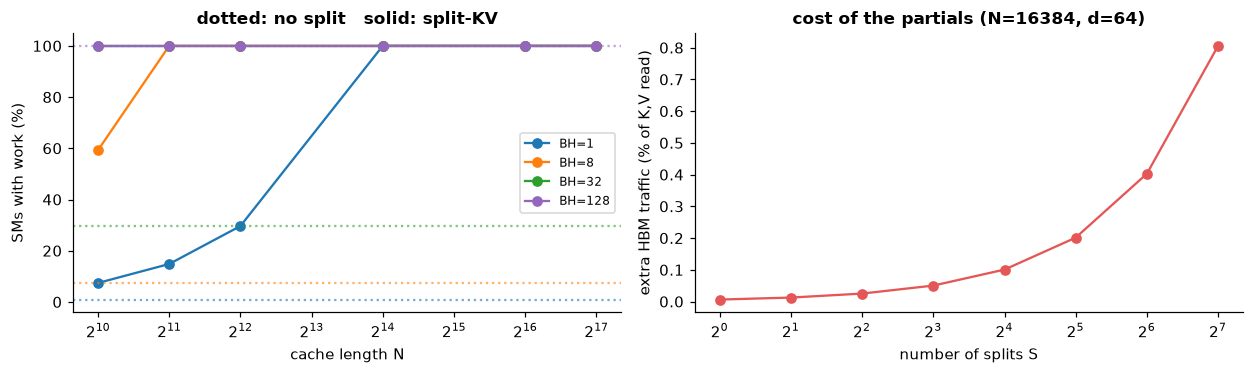

<sub>**Figure.** Left: the dotted lines are what unsplit FA-2 occupies (BH/108); solid lines are with splitting. Notice that short caches (N=1024-2048) cannot be split enough because the chunk floor limits S, so the benefit is concentrated at long N, and when BH is already >= 108 nothing changes. Right: the price is linear in S but tiny: about 0.8% at S=128 for N=16384.</sub>

In [7]:
def choose_splits(BH, N, SMs=108, cmin=128): return max(1, min(math.ceil(SMs / BH), N // cmin))
def busy_frac(items, SMs=108): return min(items, SMs) / SMs
d = 64
print(f"{'BH':>4} {'N':>7} | S  | blocks | SMs busy before -> after | extra traffic")
rows = []
for BH in (1, 8, 32, 128):
    for N in (2048, 16384, 131072):
        S_ = choose_splits(BH, N); extra = S_ * (d + 2) * 2 / (2 * N * d)             # partial write+read vs K,V read
        rows.append((BH, N, S_, busy_frac(BH), busy_frac(BH * S_), extra))
        print(f"{BH:>4} {N:>7} | {S_:>2} | {BH*S_:>6} | {busy_frac(BH)*100:>6.0f}% -> {busy_frac(BH*S_)*100:>4.0f}%        | {extra*100:.2f}%")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.5))
for BH, c in zip((1, 8, 32, 128), ("#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd")):
    Ns = np.array([1024, 2048, 4096, 16384, 65536, 131072]); axs[0].plot(Ns, [busy_frac(BH * choose_splits(BH, n)) * 100 for n in Ns], "o-", color=c, label=f"BH={BH}"); axs[0].axhline(busy_frac(BH) * 100, color=c, ls=":", alpha=.6)
axs[0].set_xscale("log", base=2); axs[0].set_xlabel("cache length N"); axs[0].set_ylabel("SMs with work (%)"); axs[0].legend(fontsize=8); axs[0].set_title("dotted: no split   solid: split-KV")
Ss = np.array([1, 2, 4, 8, 16, 32, 64, 128]); axs[1].plot(Ss, [(s * (d + 2) * 2) / (2 * 16384 * d) * 100 for s in Ss], "o-", color=COL["o"]); axs[1].set_xscale("log", base=2); axs[1].set_xlabel("number of splits S"); axs[1].set_ylabel("extra HBM traffic (% of K,V read)"); axs[1].set_title("cost of the partials (N=16384, d=64)")
plt.tight_layout(); plt.show()
caption("Left: the dotted lines are what unsplit FA-2 occupies (BH/108); solid lines are with splitting. Notice that short caches (N=1024-2048) cannot be split enough because the chunk floor limits S, so the benefit is concentrated at long N, and when BH is already >= 108 nothing changes. Right: the price is linear in S but tiny: about 0.8% at S=128 for N=16384.")
big = [r for r in rows if r[0] == 1 and r[1] == 131072][0]
check("at BH=1, N=131072 splitting fills all SMs", big[4] == 1.0 and big[3] < 0.01)
check("traffic overhead < 1% in the tested grid when chunk >= 128 keys", all(r[5] < 0.01 for r in rows), f"worst {max(r[5] for r in rows)*100:.2f}%")
HEAD["big"] = big

We found that the extra traffic stays below 1% across our grid, and the benefit is concentrated at small $BH$ and long $N$, which is the long-context, small-batch decoding case the blog post targets. The cost is real but different from traffic: a second kernel launch and a write-then-read of partials. We have not modelled launch latency, and for short caches that overhead can exceed the gain.

## 5. Ragged batches and the empty-chunk bug

**A tiny example.** In a batch, sequence 0 has 5 valid keys and sequence 1 has 4096, but both are padded to 4096. With 8 splits, 7 of sequence 0's chunks are entirely padding, so every score in those chunks is masked to $-\infty$.

**Symptom, root cause, fix.** The straightforward partial kernel computes `P = exp(S - m)` with `m = S.max()`. For an all-masked chunk, `m = -inf`, so `S - m = -inf - (-inf) = nan`, and the `nan` propagates through the merge even though that chunk should contribute exactly zero. We reproduce it, then show the guard we used above.

In [8]:
def partial_naive(q, Kc, Vc, valid):
    S = (q @ Kc.T) / math.sqrt(q.shape[-1]); S = S.masked_fill(~valid[None, :], float("-inf"))
    m = S.max(1).values; P = torch.exp(S - m[:, None]); return P @ Vc, m, P.sum(1)          # no guard

def merge_naive(parts):
    m = torch.stack([p[1] for p in parts]).max(0).values
    l = sum(torch.exp(p[1] - m) * p[2] for p in parts); Ot = sum(torch.exp(p[1] - m)[:, None] * p[0] for p in parts); return Ot / l[:, None]

N, d, S_ = 4096, 16, 8; q = torch.randn(1, d, dtype=torch.float64); K, V = torch.randn(N, d, dtype=torch.float64), torch.randn(N, d, dtype=torch.float64)
valid = torch.zeros(N, dtype=torch.bool); valid[:5] = True                                  # sequence has 5 real keys
bnd = np.linspace(0, N, S_ + 1).astype(int)
O_naive = merge_naive([partial_naive(q, K[bnd[s]:bnd[s+1]], V[bnd[s]:bnd[s+1]], valid[bnd[s]:bnd[s+1]]) for s in range(S_)])
O_fix, L_fix = flash_decode(q, K, V, S_, valid=valid); O_ref, _ = ref_attention(q, K, V, mask=valid[None, :])
print("naive  :", O_naive[0, :4].tolist()); print("guarded:", O_fix[0, :4].tolist()); print("exact  :", O_ref[0, :4].tolist())
check("unguarded empty chunks produce nan", torch.isnan(O_naive).any().item())
check("guarded merge equals masked reference", max_err(O_fix, O_ref) < 1e-12)
# a whole ragged batch
lens = [5, 700, 4096, 1]; errs = []
for ln in lens:
    vv_ = torch.zeros(N, dtype=torch.bool); vv_[:ln] = True; O_, _ = flash_decode(q, K, V, 16, valid=vv_); errs.append(max_err(O_, ref_attention(q, K, V, mask=vv_[None, :])[0]))
print("ragged lengths", lens, "errors", [f"{e:.0e}" for e in errs]); check("ragged batch exact for lengths 5/700/4096/1", max(errs) < 1e-12)

naive  : [nan, nan, nan, nan]
guarded: [-0.4792581055114629, 0.1621276632104896, 0.6818731163281706, -0.006484920648156413]
exact  : [-0.4792581055114628, 0.1621276632104896, 0.6818731163281707, -0.006484920648156339]
ragged lengths [5, 700, 4096, 1] errors ['1e-16', '8e-17', '1e-16', '0e+00']


True

The bug is a classic one for split algorithms: the empty set is a legitimate input to the merge, with $(\tilde o,m,\ell)=(0,-\infty,0)$ as its identity element. The guard in `partial_attention` and `merge_partials` implements that identity. The identity element also tells us something about *order*, which we test next.

## 6. Merge order does not matter

The merge is associative and commutative, so the partials can be combined sequentially, in a balanced tree, or in any order. This matters beyond decoding: Ring Attention (notebook 6) merges partials that arrive from different devices in a fixed rotation.

**A tiny example.** Four partials $A,B,C,D$: $((A\oplus B)\oplus C)\oplus D$ vs $(A\oplus B)\oplus(C\oplus D)$.

sequential vs ref: 2.636779683484747e-16 | tree vs ref: 2.3592239273284576e-16 | random order vs ref: 2.0816681711721685e-16


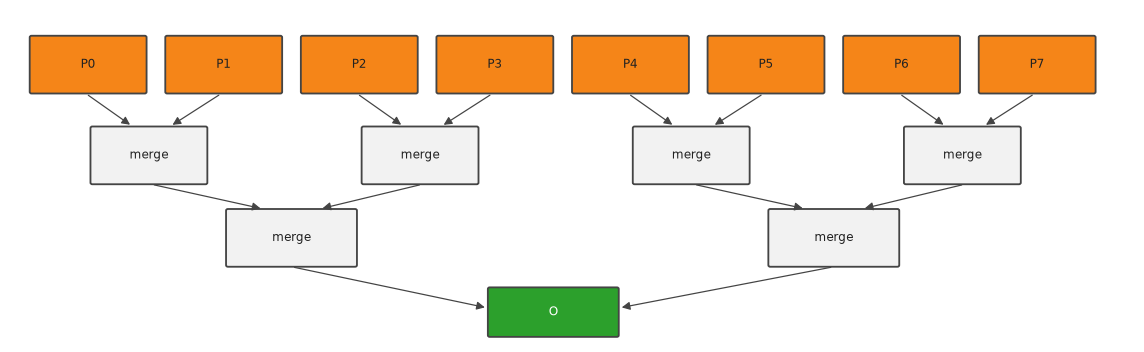

<sub>**Figure.** A balanced tree of 7 merges for 8 partials; a sequential chain would use the same 7 merges in a line. Notice that the tree has depth 3 rather than 7, which is why a reduction kernel (or a ring of devices) can combine many partials with few dependent steps.</sub>

In [9]:
def merge_unnormalised(a, b):
    """(O~,m,l) x (O~,m,l) -> (O~,m,l). The binary operator whose associativity we rely on."""
    m = torch.maximum(a[1], b[1]); ms = torch.where(torch.isinf(m), torch.zeros_like(m), m); sa, sb = torch.exp(a[1] - ms), torch.exp(b[1] - ms)
    return sa[:, None] * a[0] + sb[:, None] * b[0], m, sa * a[2] + sb * b[2]
def finish(p): return p[0] / p[2][:, None]
q = torch.randn(3, 16, dtype=torch.float64); K, V = torch.randn(1000, 16, dtype=torch.float64), torch.randn(1000, 16, dtype=torch.float64)
P_ = [partial_attention(q, K[i*125:(i+1)*125], V[i*125:(i+1)*125]) for i in range(8)]
seq = P_[0]
for p in P_[1:]: seq = merge_unnormalised(seq, p)
lvl = P_
while len(lvl) > 1: lvl = [merge_unnormalised(lvl[i], lvl[i + 1]) for i in range(0, len(lvl), 2)]
perm = torch.randperm(8).tolist(); rnd = P_[perm[0]]
for i in perm[1:]: rnd = merge_unnormalised(rnd, P_[i])
O_ref, _ = ref_attention(q, K, V)
print("sequential vs ref:", max_err(finish(seq), O_ref), "| tree vs ref:", max_err(finish(lvl[0]), O_ref), "| random order vs ref:", max_err(finish(rnd), O_ref))
check("sequential, tree and random-order merges all agree", max(max_err(finish(x), O_ref) for x in (seq, lvl[0], rnd)) < 1e-12)
empty = (torch.zeros(3, 16, dtype=torch.float64), torch.full((3,), -float("inf"), dtype=torch.float64), torch.zeros(3, dtype=torch.float64))
check("(0,-inf,0) is the identity element of the merge", all(max_err(a, b) < 1e-12 for a, b in zip(merge_unnormalised(seq, empty), seq)))
fig, ax = plt.subplots(figsize=(10.5, 3.3)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 4)
for i in range(8): box(ax, .2 + i * 1.45, 3.0, 1.25, .7, f"P{i}", COL["k"], fs=8)
for i in range(4): box(ax, .85 + i * 2.9, 1.9, 1.25, .7, "merge", COL["soft"], fs=8); arrow(ax, (.8 + 2.9 * i, 3.0), (1.3 + 2.9 * i, 2.6), lw=.8); arrow(ax, (2.25 + 2.9 * i, 3.0), (1.7 + 2.9 * i, 2.6), lw=.8)
for i in range(2): box(ax, 2.3 + i * 5.8, .9, 1.4, .7, "merge", COL["soft"], fs=8); arrow(ax, (1.5 + 5.8 * i, 1.9), (2.7 + 5.8 * i, 1.6), lw=.8); arrow(ax, (4.4 + 5.8 * i, 1.9), (3.3 + 5.8 * i, 1.6), lw=.8)
box(ax, 5.1, .05, 1.4, .6, "O", COL["good"], tc="w", fs=8); arrow(ax, (3.0, .9), (5.1, .4), lw=.8); arrow(ax, (8.8, .9), (6.5, .4), lw=.8)
plt.tight_layout(); plt.show()
caption("A balanced tree of 7 merges for 8 partials; a sequential chain would use the same 7 merges in a line. Notice that the tree has depth 3 rather than 7, which is why a reduction kernel (or a ring of devices) can combine many partials with few dependent steps.")

## 7. Cost

Pairing each benefit with its cost, all measured above except where marked:

| benefit | cost | measured how |
|---|---|---|
| fills SMs at small batch*heads: `BH=1, N=131072` goes from <1% to 100% SMs busy (model) | second kernel (launch, write+read of partials) | not measured (no GPU); traffic part counted |
| exact for any split count and merge order | needs identity-handling for empty chunks; one extra bug class | verified, 7 split counts + ragged batch |
| extra HBM traffic < 1% when chunks >= 128 keys | partial buffer of $S(d+2)$ numbers per head | counted formula, N up to 131072 |
| up to 8x faster at very long context | – | *reported* in the Flash-Decoding blog, not measured here |

In [10]:
n = HEAD["big"]
display(Markdown(f"Headline from this notebook's measurements: at batch*heads=1, N=131072 the heuristic picks S={n[2]} splits, taking SM occupancy in our model from {n[3]*100:.1f}% to {n[4]*100:.0f}% for {n[5]*100:.2f}% extra traffic, and every split count we tried reproduces the unsplit output to {max(split_errs.values()):.0e} in float64."))

Headline from this notebook's measurements: at batch*heads=1, N=131072 the heuristic picks S=108 splits, taking SM occupancy in our model from 0.9% to 100% for 0.08% extra traffic, and every split count we tried reproduces the unsplit output to 2e-16 in float64.

## 8. Closing thoughts

Flash-Decoding is the smallest of the variants in this series and the one whose idea travels furthest: once attention is expressed as an associative merge of $(\tilde o,m,\ell)$ triples, splitting along keys is only a choice of where to cut. The same merge appears in Ring Attention across devices and in sequence-parallel inference. Our measurement shows exactness and small traffic overhead; what it cannot show is the speedup, which depends on how many bytes per second a single SM can pull from HBM, a number we did not measure.

**Still open.** Interaction with paged KV caches (chunks then align to pages, which may force $c_{\min}$ to the page size); grouped-query attention, where several query heads share a K/V chunk and the arithmetic intensity rises (notebook 5 covers GQA numerics but not decoding performance); and picking $S$ well on real hardware, where our heuristic is a placeholder.

Checks run in this notebook:

In [11]:
report()

PASS decoding attention is far below the ~200 FLOP/byte ridge point
PASS tiny merge equals direct attention
PASS merge_partials reproduces full attention (2 uneven chunks)
PASS split-KV exact with 1 splits (incl. uneven)   [err=1.6e-16]
PASS split-KV exact with 2 splits (incl. uneven)   [err=1.2e-16]
PASS split-KV exact with 3 splits (incl. uneven)   [err=8.3e-17]
PASS split-KV exact with 7 splits (incl. uneven)   [err=1.1e-16]
PASS split-KV exact with 16 splits (incl. uneven)   [err=9.0e-17]
PASS split-KV exact with 33 splits (incl. uneven)   [err=8.8e-17]
PASS split-KV exact with 128 splits (incl. uneven)   [err=1.1e-16]
PASS works for Nq>1 (e.g. speculative decoding, Nq=4)
PASS at BH=1, N=131072 splitting fills all SMs
PASS traffic overhead < 1% in the tested grid when chunk >= 128 keys   [worst 0.81%]
PASS unguarded empty chunks produce nan
PASS guarded merge equals masked reference
PASS ragged batch exact for lengths 5/700/4096/1
PASS sequential, tree and random-order merges all a